In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving ecommerce_return_insight_dataset.zip to ecommerce_return_insight_dataset.zip


In [3]:
zip_file = next(
    filename
    for filename in uploaded
    if filename.endswith(".zip")
)

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall("/content/ecommerce_dataset")

DATA_DIR = "/content/ecommerce_dataset"

print("Dataset extracted successfully!")

print(os.listdir(DATA_DIR))

Dataset extracted successfully!
['customers.csv', 'delivery.csv', 'products.csv', 'README.txt', 'returns.csv', 'orders.csv']


In [4]:
orders = pd.read_csv(
    f"{DATA_DIR}/orders.csv"
)

products = pd.read_csv(
    f"{DATA_DIR}/products.csv"
)

customers = pd.read_csv(
    f"{DATA_DIR}/customers.csv"
)

delivery = pd.read_csv(
    f"{DATA_DIR}/delivery.csv"
)

returns = pd.read_csv(
    f"{DATA_DIR}/returns.csv"
)

print("All five datasets loaded successfully!")

All five datasets loaded successfully!


In [5]:
print("ORDERS DATASET")
display(orders.head())

print("PRODUCTS DATASET")
display(products.head())

print("CUSTOMERS DATASET")
display(customers.head())

print("DELIVERY DATASET")
display(delivery.head())

print("RETURNS DATASET")
display(returns.head())

ORDERS DATASET


,order_id,order_date,product_id,customer_id,quantity,price,discount
0,O00001,2025-02-28,P046,C0001,4,5959.87,10.0
1,O00002,2025-06-09,P004,C0100,2,860.28,5.0
2,O00003,2025-06-17,P048,C0159,3,9943.60,30.0
3,O00004,2025-06-26,P020,C0104,3,2819.49,20.0
4,O00005,2025-01-07,P040,C0150,3,2888.43,30.0


PRODUCTS DATASET


,product_id,category,brand,size,seller_id,product_name
0,P001,Clothing,UrbanThread,m,S008,Clothing Item 01
1,P002,Footwear,WalkWell,8,S011,Footwear Item 02
2,P003,Electronics,NovaTech,NaN,S009,Electronics Item 03
3,P004,Home & Kitchen,CasaBloom,NaN,S002,Home Item 04
4,P005,Beauty,PureAura,NaN,S012,Beauty Item 05


CUSTOMERS DATASET


,customer_id,region,order_history,customer_segment
0,C0001,Central,1,New
1,C0002,South,6,Returning
2,C0003,West,4,Loyal
3,C0004,West,14,Returning
4,C0005,West,9,New


DELIVERY DATASET


,order_id,promised_date,delivered_date,courier
0,O00001,2025-03-04,2025-03-05,ParcelPro
1,O00002,2025-06-14,2025-06-14,BlueRoute
2,O00003,2025-06-19,2025-06-19,BlueRoute
3,O00004,2025-06-29,2025-07-03,QuickKart
4,O00005,2025-01-11,2025-01-14,ParcelPro


RETURNS DATASET


,return_id,order_id,return_flag,reason,return_date
0,R00001,O00006,1,Wrong size,2025-03-30
1,R00002,O00013,1,Not as described,2025-04-16
2,R00003,O00020,1,Wrong size,2025-08-14
3,R00004,O00024,1,NaN,2025-05-03
4,R00005,O00027,1,NaN,2025-10-09


In [6]:
datasets = {
    "Orders": orders,
    "Products": products,
    "Customers": customers,
    "Delivery": delivery,
    "Returns": returns
}

for name, df in datasets.items():

    print("\nDataset:", name)

    print("Rows:", df.shape[0])

    print("Columns:", df.shape[1])


Dataset: Orders
Rows: 601
Columns: 7

Dataset: Products
Rows: 60
Columns: 6

Dataset: Customers
Rows: 250
Columns: 4

Dataset: Delivery
Rows: 601
Columns: 4

Dataset: Returns
Rows: 601
Columns: 5


In [7]:
for name, df in datasets.items():

    print("\n", "=" * 50)

    print(name)

    print("=" * 50)

    df.info()


Orders
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 601 entries, 0 to 600
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   order_id     601 non-null    object 
 1   order_date   601 non-null    object 
 2   product_id   601 non-null    object 
 3   customer_id  601 non-null    object 
 4   quantity     601 non-null    int64  
 5   price        601 non-null    float64
 6   discount     601 non-null    float64
dtypes: float64(2), int64(1), object(4)
memory usage: 33.0+ KB

Products
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   product_id    60 non-null     object
 1   category      60 non-null     object
 2   brand         60 non-null     object
 3   size          24 non-null     object
 4   seller_id     60 non-null     object
 5   product_name  60 non-null     object

In [8]:
print("Orders Statistical Summary")

display(orders.describe())

print("Products Summary")

display(products.describe(include="all"))

print("Customers Summary")

display(customers.describe(include="all"))

Orders Statistical Summary


,quantity,price,discount
count,601.000000,601.000000,601.000000
mean,2.560732,4623.226522,15.391015
std,1.122522,4915.605714,14.524870
min,1.000000,121.980000,-10.000000
25%,2.000000,1774.900000,5.000000
50%,3.000000,3333.810000,15.000000
75%,4.000000,5209.250000,20.000000
max,4.000000,24983.870000,250.000000


Products Summary


,product_id,category,brand,size,seller_id,product_name
count,60,60,60,24,60,60
unique,60,5,15,9,12,60
top,P001,Clothing,ByteWave,L,S010,Clothing Item 01
freq,1,12,6,7,8,1


Customers Summary


,customer_id,region,order_history,customer_segment
count,250,250,250.00000,250
unique,250,5,NaN,3
top,C0001,West,NaN,Returning
freq,1,67,NaN,104
mean,NaN,NaN,12.47200,NaN
std,NaN,NaN,7.10741,NaN
min,NaN,NaN,1.00000,NaN
25%,NaN,NaN,6.00000,NaN
50%,NaN,NaN,13.00000,NaN
75%,NaN,NaN,19.00000,NaN


In [9]:
for name, df in datasets.items():

    print("\nDataset:", name)

    print(df.isnull().sum())


Dataset: Orders
order_id       0
order_date     0
product_id     0
customer_id    0
quantity       0
price          0
discount       0
dtype: int64

Dataset: Products
product_id       0
category         0
brand            0
size            36
seller_id        0
product_name     0
dtype: int64

Dataset: Customers
customer_id         0
region              0
order_history       0
customer_segment    0
dtype: int64

Dataset: Delivery
order_id          0
promised_date     0
delivered_date    0
courier           0
dtype: int64

Dataset: Returns
return_id        0
order_id         0
return_flag      0
reason         480
return_date    463
dtype: int64


In [10]:
for name, df in datasets.items():

    print(
        name,
        "Duplicate Rows:",
        df.duplicated().sum()
    )

Orders Duplicate Rows: 1
Products Duplicate Rows: 0
Customers Duplicate Rows: 0
Delivery Duplicate Rows: 0
Returns Duplicate Rows: 0


In [11]:
invalid_discounts = orders[
    (orders["discount"] < 0) |
    (orders["discount"] > 100)
]

display(invalid_discounts)

,order_id,order_date,product_id,customer_id,quantity,price,discount
17,O00018,2025-06-01,P055,C0186,1,3297.27,125.0
132,O00133,2025-03-28,P051,C0095,2,4646.56,-10.0
401,O00402,2025-02-24,P036,C0056,4,4542.13,250.0


In [12]:
orders_clean = orders.copy()

products_clean = products.copy()

customers_clean = customers.copy()

delivery_clean = delivery.copy()

returns_clean = returns.copy()

print("Clean datasets created!")

Clean datasets created!


In [13]:
print("Before:", len(orders_clean))

orders_clean = orders_clean.drop_duplicates(
    subset="order_id",
    keep="first"
)

print("After:", len(orders_clean))

Before: 601
After: 600


In [14]:
products_clean["size"] = (
    products_clean["size"]
    .astype("string")
    .str.strip()
    .str.upper()
)

products_clean["size"] = products_clean["size"].replace({
    "MEDIUM": "M",
    "SMALL": "S",
    "LARGE": "L",
    "EXTRA LARGE": "XL"
})

display(products_clean.head(10))

,product_id,category,brand,size,seller_id,product_name
0,P001,Clothing,UrbanThread,M,S008,Clothing Item 01
1,P002,Footwear,WalkWell,8,S011,Footwear Item 02
2,P003,Electronics,NovaTech,<NA>,S009,Electronics Item 03
3,P004,Home & Kitchen,CasaBloom,<NA>,S002,Home Item 04
4,P005,Beauty,PureAura,<NA>,S012,Beauty Item 05
5,P006,Clothing,StyleNest,XL,S009,Clothing Item 06
6,P007,Footwear,SoleCraft,8,S002,Footwear Item 07
7,P008,Electronics,VoltEdge,<NA>,S006,Electronics Item 08
8,P009,Home & Kitchen,KitchenPro,<NA>,S005,Home Item 09
9,P010,Beauty,GlowLab,<NA>,S012,Beauty Item 10


In [15]:
invalid_mask = (
    (orders_clean["discount"] < 0) |
    (orders_clean["discount"] > 100)
)

orders_clean.loc[
    invalid_mask,
    "discount"
] = np.nan

orders_clean["discount"] = (
    orders_clean["discount"]
    .fillna(orders_clean["discount"].median())
)

print("Discount cleaning completed!")

print(orders_clean["discount"].describe())

Discount cleaning completed!
count    600.000000
mean      14.841667
std        9.891731
min        0.000000
25%        8.750000
50%       15.000000
75%       20.000000
max       40.000000
Name: discount, dtype: float64


In [16]:
orders_clean["order_date"] = pd.to_datetime(
    orders_clean["order_date"],
    errors="coerce"
)

delivery_clean["promised_date"] = pd.to_datetime(
    delivery_clean["promised_date"],
    errors="coerce"
)

delivery_clean["delivered_date"] = pd.to_datetime(
    delivery_clean["delivered_date"],
    errors="coerce"
)

returns_clean["return_date"] = pd.to_datetime(
    returns_clean["return_date"],
    errors="coerce"
)

print("Date conversion completed!")

Date conversion completed!


In [17]:
delivery_check = delivery_clean.merge(
    orders_clean[["order_id", "order_date"]],
    on="order_id",
    how="left"
)

invalid_mask = (
    delivery_check["delivered_date"].notna() &
    delivery_check["order_date"].notna() &
    (
        delivery_check["delivered_date"] <
        delivery_check["order_date"]
    )
)

invalid_ids = delivery_check.loc[
    invalid_mask,
    "order_id"
]

delivery_clean.loc[
    delivery_clean["order_id"].isin(invalid_ids),
    "delivered_date"
] = pd.NaT

print("Invalid delivery dates handled!")

Invalid delivery dates handled!


In [18]:
delivery_check = delivery_clean.merge(
    orders_clean[["order_id", "order_date"]],
    on="order_id",
    how="left"
)

invalid_mask = (
    delivery_check["delivered_date"].notna() &
    delivery_check["order_date"].notna() &
    (
        delivery_check["delivered_date"] <
        delivery_check["order_date"]
    )
)

invalid_ids = delivery_check.loc[
    invalid_mask,
    "order_id"
]

delivery_clean.loc[
    delivery_clean["order_id"].isin(invalid_ids),
    "delivered_date"
] = pd.NaT

print("Invalid delivery dates handled!")

Invalid delivery dates handled!


In [19]:
master_df = orders_clean.merge(
    products_clean,
    on="product_id",
    how="left",
    validate="many_to_one"
)

print(master_df.shape)

(600, 12)


In [20]:
master_df = master_df.merge(
    customers_clean,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print(master_df.shape)

(600, 15)


In [22]:
# Check duplicate order IDs in delivery dataset
duplicate_delivery = delivery_clean[
    delivery_clean.duplicated(
        subset=["order_id"],
        keep=False
    )
]

print("Duplicate delivery records:")
display(duplicate_delivery)

Duplicate delivery records:


,order_id,promised_date,delivered_date,courier
24,O00025,2025-08-23,2025-08-26,QuickKart
600,O00025,2025-08-26,2025-08-28,QuickKart


In [23]:
print("Before cleaning:", len(delivery_clean))

delivery_clean = delivery_clean.drop_duplicates(
    subset=["order_id"],
    keep="first"
)

print("After cleaning:", len(delivery_clean))

print(
    "Remaining duplicate order IDs:",
    delivery_clean["order_id"].duplicated().sum()
)

Before cleaning: 601
After cleaning: 600
Remaining duplicate order IDs: 0


In [24]:
master_df = master_df.merge(
    delivery_clean[
        [
            "order_id",
            "promised_date",
            "delivered_date",
            "courier"
        ]
    ],
    on="order_id",
    how="left",
    validate="one_to_one"
)

print("Delivery dataset merged successfully!")
print("Master dataset shape:", master_df.shape)

display(master_df.head())

Delivery dataset merged successfully!
Master dataset shape: (600, 18)


,order_id,order_date,product_id,customer_id,quantity,price,discount,category,brand,size,seller_id,product_name,region,order_history,customer_segment,promised_date,delivered_date,courier
0,O00001,2025-02-28,P046,C0001,4,5959.87,10.0,Clothing,CottonCo,L,S004,Clothing Item 46,Central,1,New,2025-03-04,2025-03-05,ParcelPro
1,O00002,2025-06-09,P004,C0100,2,860.28,5.0,Home & Kitchen,CasaBloom,<NA>,S002,Home Item 04,Central,8,Returning,2025-06-14,2025-06-14,BlueRoute
2,O00003,2025-06-17,P048,C0159,3,9943.60,30.0,Electronics,ByteWave,<NA>,S007,Electronics Item 48,Central,4,Returning,2025-06-19,2025-06-19,BlueRoute
3,O00004,2025-06-26,P020,C0104,3,2819.49,20.0,Beauty,PureAura,<NA>,S011,Beauty Item 20,West,16,New,2025-06-29,2025-07-03,QuickKart
4,O00005,2025-01-07,P040,C0150,3,2888.43,30.0,Beauty,SkinKind,<NA>,S004,Beauty Item 40,West,5,Loyal,2025-01-11,2025-01-14,ParcelPro


In [25]:
# Check duplicate order IDs in returns dataset

print(
    "Duplicate order IDs in returns:",
    returns_clean["order_id"].duplicated().sum()
)

Duplicate order IDs in returns: 1


In [27]:
# Check duplicate order IDs in returns dataset

duplicate_returns = returns_clean[
    returns_clean.duplicated(
        subset=["order_id"],
        keep=False
    )
].sort_values("order_id")

print("Duplicate return records:")
display(duplicate_returns)

print(
    "Total duplicate order IDs:",
    returns_clean["order_id"].duplicated().sum()
)

Duplicate return records:


,return_id,order_id,return_flag,reason,return_date
158,R00159,O00025,0,NaN,NaT
600,R00601,O00025,0,NaN,NaT


Total duplicate order IDs: 1


In [28]:
print("Before cleaning:", len(returns_clean))

returns_clean = returns_clean.drop_duplicates(
    subset=["order_id"],
    keep="first"
)

print("After cleaning:", len(returns_clean))

print(
    "Remaining duplicate order IDs:",
    returns_clean["order_id"].duplicated().sum()
)

Before cleaning: 601
After cleaning: 600
Remaining duplicate order IDs: 0


In [29]:
master_df = master_df.merge(
    returns_clean[
        [
            "order_id",
            "return_flag",
            "reason",
            "return_date"
        ]
    ],
    on="order_id",
    how="left",
    validate="one_to_one"
)

print("Returns dataset merged successfully!")

print("Master dataset shape:", master_df.shape)

display(master_df.head())

Returns dataset merged successfully!
Master dataset shape: (600, 21)


,order_id,order_date,product_id,customer_id,quantity,price,discount,category,brand,size,...,product_name,region,order_history,customer_segment,promised_date,delivered_date,courier,return_flag,reason,return_date
0,O00001,2025-02-28,P046,C0001,4,5959.87,10.0,Clothing,CottonCo,L,...,Clothing Item 46,Central,1,New,2025-03-04,2025-03-05,ParcelPro,0,NaN,NaT
1,O00002,2025-06-09,P004,C0100,2,860.28,5.0,Home & Kitchen,CasaBloom,<NA>,...,Home Item 04,Central,8,Returning,2025-06-14,2025-06-14,BlueRoute,0,NaN,NaT
2,O00003,2025-06-17,P048,C0159,3,9943.60,30.0,Electronics,ByteWave,<NA>,...,Electronics Item 48,Central,4,Returning,2025-06-19,2025-06-19,BlueRoute,0,NaN,NaT
3,O00004,2025-06-26,P020,C0104,3,2819.49,20.0,Beauty,PureAura,<NA>,...,Beauty Item 20,West,16,New,2025-06-29,2025-07-03,QuickKart,0,NaN,NaT
4,O00005,2025-01-07,P040,C0150,3,2888.43,30.0,Beauty,SkinKind,<NA>,...,Beauty Item 40,West,5,Loyal,2025-01-11,2025-01-14,ParcelPro,0,NaN,NaT


In [31]:
print("Dataset Shape:", master_df.shape)

print("\nColumn Names:")
print(master_df.columns.tolist())

print("\nFirst 5 Records:")
display(master_df.head())

Dataset Shape: (600, 24)

Column Names:
['order_id', 'order_date', 'product_id', 'customer_id', 'quantity', 'price', 'discount', 'category', 'brand', 'size', 'seller_id', 'product_name', 'region', 'order_history', 'customer_segment', 'promised_date', 'delivered_date', 'courier', 'return_flag_x', 'reason_x', 'return_date_x', 'return_flag_y', 'reason_y', 'return_date_y']

First 5 Records:


,order_id,order_date,product_id,customer_id,quantity,price,discount,category,brand,size,...,customer_segment,promised_date,delivered_date,courier,return_flag_x,reason_x,return_date_x,return_flag_y,reason_y,return_date_y
0,O00001,2025-02-28,P046,C0001,4,5959.87,10.0,Clothing,CottonCo,L,...,New,2025-03-04,2025-03-05,ParcelPro,0,NaN,NaT,0,NaN,NaT
1,O00002,2025-06-09,P004,C0100,2,860.28,5.0,Home & Kitchen,CasaBloom,<NA>,...,Returning,2025-06-14,2025-06-14,BlueRoute,0,NaN,NaT,0,NaN,NaT
2,O00003,2025-06-17,P048,C0159,3,9943.60,30.0,Electronics,ByteWave,<NA>,...,Returning,2025-06-19,2025-06-19,BlueRoute,0,NaN,NaT,0,NaN,NaT
3,O00004,2025-06-26,P020,C0104,3,2819.49,20.0,Beauty,PureAura,<NA>,...,New,2025-06-29,2025-07-03,QuickKart,0,NaN,NaT,0,NaN,NaT
4,O00005,2025-01-07,P040,C0150,3,2888.43,30.0,Beauty,SkinKind,<NA>,...,Loyal,2025-01-11,2025-01-14,ParcelPro,0,NaN,NaT,0,NaN,NaT


In [32]:
print(
    "Duplicate Order IDs:",
    master_df["order_id"].duplicated().sum()
)

print(
    "Unique Order IDs:",
    master_df["order_id"].nunique()
)

Duplicate Order IDs: 0
Unique Order IDs: 600


In [33]:
missing_values = master_df.isnull().sum()

print("Missing Values in Each Column:")

display(
    missing_values[missing_values > 0]
)

Missing Values in Each Column:


,0
size,336
delivered_date,2
reason_x,479
return_date_x,462
reason_y,479
return_date_y,462


In [34]:
master_df["order_value"] = (
    master_df["quantity"]
    * master_df["price"]
    * (1 - master_df["discount"] / 100)
)

master_df["order_value"] = master_df["order_value"].round(2)

display(
    master_df[
        [
            "order_id",
            "quantity",
            "price",
            "discount",
            "order_value"
        ]
    ].head(10)
)

,order_id,quantity,price,discount,order_value
0,O00001,4,5959.87,10.0,21455.53
1,O00002,2,860.28,5.0,1634.53
2,O00003,3,9943.60,30.0,20881.56
3,O00004,3,2819.49,20.0,6766.78
4,O00005,3,2888.43,30.0,6065.70
5,O00006,1,4099.75,25.0,3074.81
6,O00007,3,2751.83,30.0,5778.84
7,O00008,4,3234.34,20.0,10349.89
8,O00009,3,5689.46,10.0,15361.54
9,O00010,2,3413.73,20.0,5461.97


In [35]:
master_df["promised_date"] = pd.to_datetime(
    master_df["promised_date"],
    errors="coerce"
)

master_df["delivered_date"] = pd.to_datetime(
    master_df["delivered_date"],
    errors="coerce"
)

master_df["delivery_delay_days"] = (
    master_df["delivered_date"]
    - master_df["promised_date"]
).dt.days

display(
    master_df[
        [
            "order_id",
            "promised_date",
            "delivered_date",
            "delivery_delay_days"
        ]
    ].head(10)
)

,order_id,promised_date,delivered_date,delivery_delay_days
0,O00001,2025-03-04,2025-03-05,1.0
1,O00002,2025-06-14,2025-06-14,0.0
2,O00003,2025-06-19,2025-06-19,0.0
3,O00004,2025-06-29,2025-07-03,4.0
4,O00005,2025-01-11,2025-01-14,3.0
5,O00006,2025-03-25,2025-03-28,3.0
6,O00007,2025-08-22,2025-08-29,7.0
7,O00008,2025-03-10,2025-03-11,1.0
8,O00009,2025-03-24,2025-03-27,3.0
9,O00010,2025-03-31,2025-04-03,3.0


In [37]:
print(master_df.columns.tolist())

['order_id', 'order_date', 'product_id', 'customer_id', 'quantity', 'price', 'discount', 'category', 'brand', 'size', 'seller_id', 'product_name', 'region', 'order_history', 'customer_segment', 'promised_date', 'delivered_date', 'courier', 'return_flag_x', 'reason_x', 'return_date_x', 'return_flag_y', 'reason_y', 'return_date_y', 'order_value', 'delivery_delay_days']


In [38]:
print("Return Flag X:")
print(master_df["return_flag_x"].value_counts(dropna=False))

print("\nReturn Flag Y:")
print(master_df["return_flag_y"].value_counts(dropna=False))

Return Flag X:
return_flag_x
0    462
1    138
Name: count, dtype: int64

Return Flag Y:
return_flag_y
0    462
1    138
Name: count, dtype: int64


In [39]:
print(
    "Return flags identical:",
    master_df["return_flag_x"].equals(
        master_df["return_flag_y"]
    )
)

print(
    "Return reasons identical:",
    master_df["reason_x"].equals(
        master_df["reason_y"]
    )
)

Return flags identical: True
Return reasons identical: True


In [40]:
# Keep one copy of each return-related column
master_df["return_flag"] = (
    master_df["return_flag_x"]
    .combine_first(master_df["return_flag_y"])
)

master_df["reason"] = (
    master_df["reason_x"]
    .combine_first(master_df["reason_y"])
)

master_df["return_date"] = (
    master_df["return_date_x"]
    .combine_first(master_df["return_date_y"])
)

# Remove redundant columns
master_df.drop(
    columns=[
        "return_flag_x",
        "return_flag_y",
        "reason_x",
        "reason_y",
        "return_date_x",
        "return_date_y"
    ],
    inplace=True
)

print("Duplicate return columns removed!")

print(master_df.columns.tolist())

Duplicate return columns removed!
['order_id', 'order_date', 'product_id', 'customer_id', 'quantity', 'price', 'discount', 'category', 'brand', 'size', 'seller_id', 'product_name', 'region', 'order_history', 'customer_segment', 'promised_date', 'delivered_date', 'courier', 'order_value', 'delivery_delay_days', 'return_flag', 'reason', 'return_date']


In [41]:
master_df["is_returned"] = (
    master_df["return_flag"]
    .fillna(0)
    .astype(int)
)

print("Return Status:")
print(master_df["is_returned"].value_counts())

display(
    master_df[
        [
            "order_id",
            "return_flag",
            "is_returned",
            "reason"
        ]
    ].head(10)
)

Return Status:
is_returned
0    462
1    138
Name: count, dtype: int64


,order_id,return_flag,is_returned,reason
0,O00001,0,0,NaN
1,O00002,0,0,NaN
2,O00003,0,0,NaN
3,O00004,0,0,NaN
4,O00005,0,0,NaN
5,O00006,1,1,Wrong size
6,O00007,0,0,NaN
7,O00008,0,0,NaN
8,O00009,0,0,NaN
9,O00010,0,0,NaN


In [42]:
# Calculate order value
master_df["order_value"] = (
    master_df["quantity"]
    * master_df["price"]
    * (1 - master_df["discount"] / 100)
).round(2)

# Convert date columns
master_df["order_date"] = pd.to_datetime(
    master_df["order_date"],
    errors="coerce"
)

master_df["promised_date"] = pd.to_datetime(
    master_df["promised_date"],
    errors="coerce"
)

master_df["delivered_date"] = pd.to_datetime(
    master_df["delivered_date"],
    errors="coerce"
)

# Calculate delivery delay
master_df["delivery_delay_days"] = (
    master_df["delivered_date"]
    - master_df["promised_date"]
).dt.days

# Identify late deliveries
master_df["delivery_status"] = np.select(
    [
        master_df["delivery_delay_days"].isna(),
        master_df["delivery_delay_days"] > 0,
        master_df["delivery_delay_days"] == 0,
        master_df["delivery_delay_days"] < 0
    ],
    [
        "Unknown",
        "Late",
        "On Time",
        "Early"
    ],
    default="Unknown"
)

# Extract order month
master_df["order_month"] = (
    master_df["order_date"].dt.month
)

print("Feature engineering completed!")

display(master_df.head())

Feature engineering completed!


,order_id,order_date,product_id,customer_id,quantity,price,discount,category,brand,size,...,delivered_date,courier,order_value,delivery_delay_days,return_flag,reason,return_date,is_returned,delivery_status,order_month
0,O00001,2025-02-28,P046,C0001,4,5959.87,10.0,Clothing,CottonCo,L,...,2025-03-05,ParcelPro,21455.53,1.0,0,NaN,NaT,0,Late,2
1,O00002,2025-06-09,P004,C0100,2,860.28,5.0,Home & Kitchen,CasaBloom,<NA>,...,2025-06-14,BlueRoute,1634.53,0.0,0,NaN,NaT,0,On Time,6
2,O00003,2025-06-17,P048,C0159,3,9943.60,30.0,Electronics,ByteWave,<NA>,...,2025-06-19,BlueRoute,20881.56,0.0,0,NaN,NaT,0,On Time,6
3,O00004,2025-06-26,P020,C0104,3,2819.49,20.0,Beauty,PureAura,<NA>,...,2025-07-03,QuickKart,6766.78,4.0,0,NaN,NaT,0,Late,6
4,O00005,2025-01-07,P040,C0150,3,2888.43,30.0,Beauty,SkinKind,<NA>,...,2025-01-14,ParcelPro,6065.70,3.0,0,NaN,NaT,0,Late,1


In [43]:
total_orders = master_df["order_id"].nunique()

returned_orders = master_df.loc[
    master_df["is_returned"] == 1,
    "order_id"
].nunique()

overall_return_rate = (
    returned_orders / total_orders * 100
    if total_orders > 0
    else 0
)

print("Total Orders:", total_orders)
print("Returned Orders:", returned_orders)
print(f"Overall Return Rate: {overall_return_rate:.2f}%")

Total Orders: 600
Returned Orders: 138
Overall Return Rate: 23.00%


In [44]:
category_analysis = (
    master_df.groupby("category")
    .agg(
        total_orders=("order_id", "nunique"),
        returned_orders=("is_returned", "sum")
    )
)

category_analysis["return_rate"] = (
    category_analysis["returned_orders"]
    / category_analysis["total_orders"]
) * 100

category_analysis = category_analysis.sort_values(
    "return_rate",
    ascending=False
)

display(category_analysis)

,total_orders,returned_orders,return_rate
category,,,
Home & Kitchen,116,33,28.448276
Clothing,143,33,23.076923
Electronics,102,23,22.549020
Footwear,121,26,21.487603
Beauty,118,23,19.491525


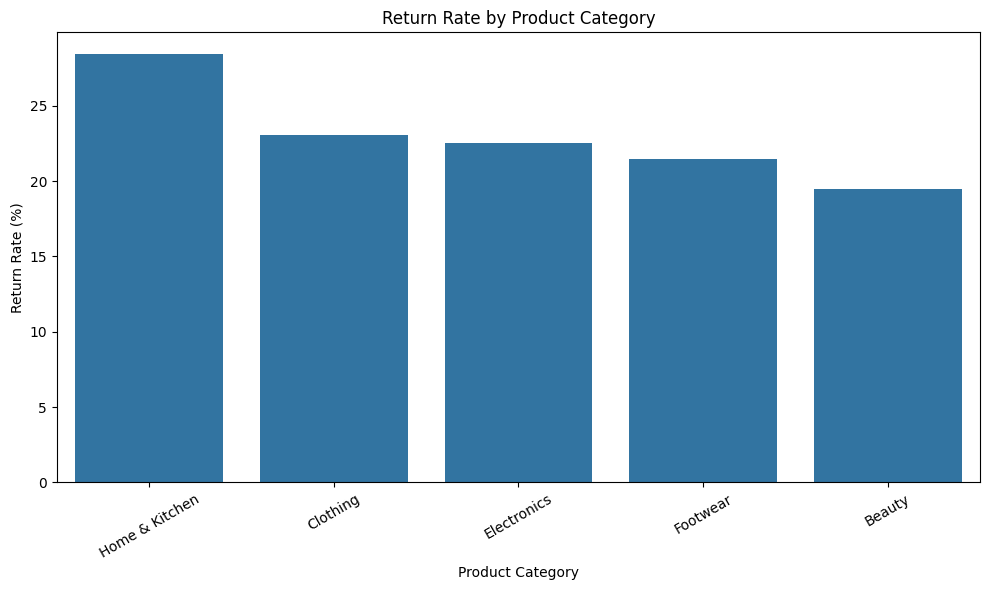

In [45]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_analysis.reset_index(),
    x="category",
    y="return_rate"
)

plt.title("Return Rate by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Return Rate (%)")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [46]:
master_df["discount_category"] = pd.cut(
    master_df["discount"],
    bins=[-0.01, 0, 10, 20, 30, 100],
    labels=[
        "No Discount",
        "Low Discount",
        "Medium Discount",
        "High Discount",
        "Very High Discount"
    ]
)

discount_analysis = (
    master_df.groupby(
        "discount_category",
        observed=True
    )
    .agg(
        total_orders=("order_id", "nunique"),
        returned_orders=("is_returned", "sum")
    )
)

discount_analysis["return_rate"] = (
    discount_analysis["returned_orders"]
    / discount_analysis["total_orders"]
) * 100

display(discount_analysis)

,total_orders,returned_orders,return_rate
discount_category,,,
No Discount,83,18,21.686747
Low Discount,173,40,23.121387
Medium Discount,202,56,27.722772
High Discount,127,21,16.535433
Very High Discount,15,3,20.000000


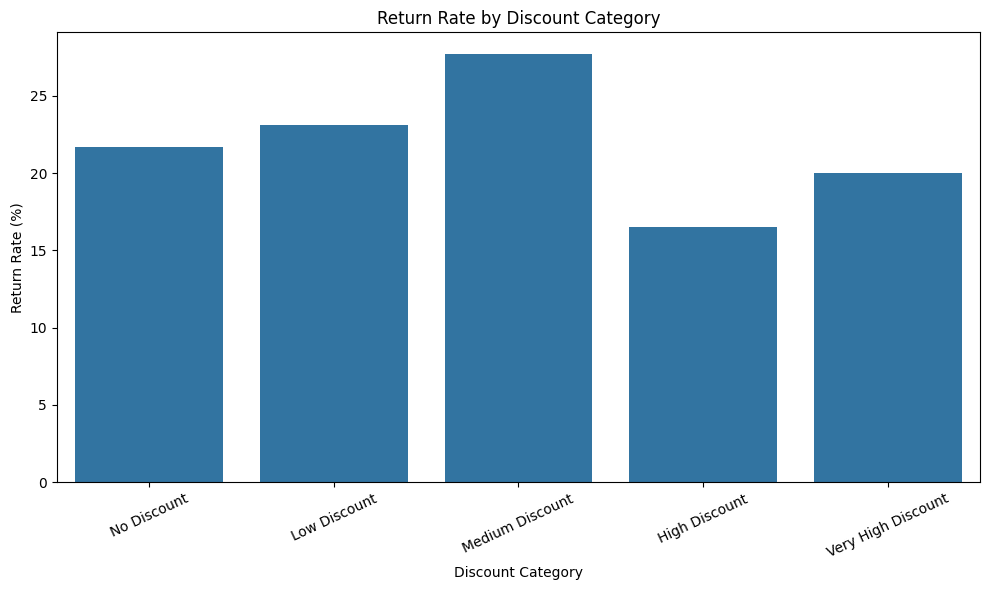

In [47]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=discount_analysis.reset_index(),
    x="discount_category",
    y="return_rate"
)

plt.title("Return Rate by Discount Category")
plt.xlabel("Discount Category")
plt.ylabel("Return Rate (%)")

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [48]:
delivery_analysis = (
    master_df[
        master_df["delivery_delay_days"].notna()
    ]
    .groupby("delivery_status")
    .agg(
        total_orders=("order_id", "nunique"),
        returned_orders=("is_returned", "sum")
    )
)

delivery_analysis["return_rate"] = (
    delivery_analysis["returned_orders"]
    / delivery_analysis["total_orders"]
) * 100

display(delivery_analysis)

,total_orders,returned_orders,return_rate
delivery_status,,,
Early,14,3,21.428571
Late,448,102,22.767857
On Time,136,32,23.529412


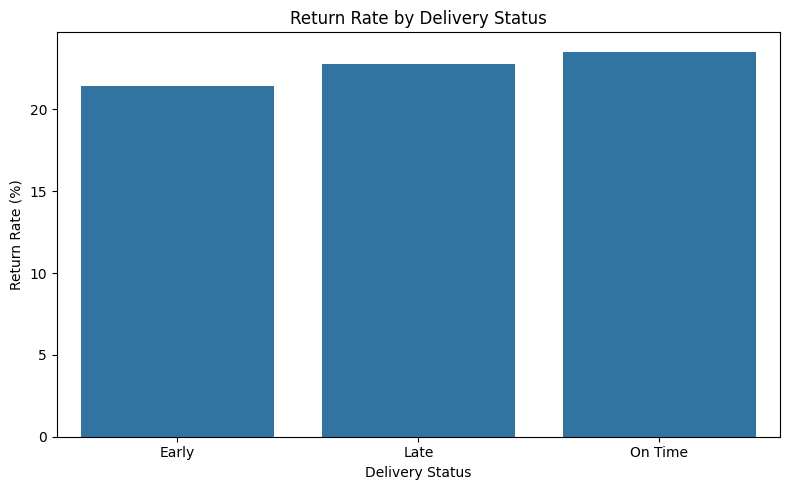

In [49]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=delivery_analysis.reset_index(),
    x="delivery_status",
    y="return_rate"
)

plt.title("Return Rate by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Return Rate (%)")

plt.tight_layout()
plt.show()

In [50]:
returned_df = master_df[
    master_df["is_returned"] == 1
].copy()

reason_analysis = (
    returned_df["reason"]
    .fillna("Unknown")
    .value_counts()
)

display(reason_analysis)

,count
reason,
Damaged product,33
Wrong size,32
Not as described,23
Late delivery,20
Unknown,17
Changed mind,7
Wrong item,6


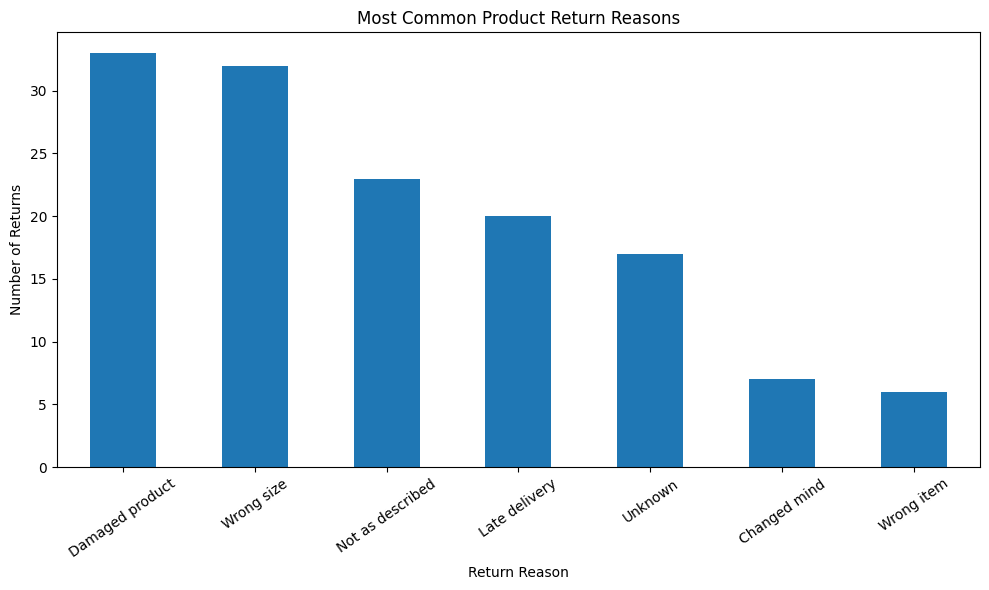

In [51]:
plt.figure(figsize=(10, 6))

reason_analysis.plot(kind="bar")

plt.title("Most Common Product Return Reasons")
plt.xlabel("Return Reason")
plt.ylabel("Number of Returns")

plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

In [52]:
seller_analysis = (
    master_df.groupby("seller_id")
    .agg(
        total_orders=("order_id", "nunique"),
        returned_orders=("is_returned", "sum")
    )
)

seller_analysis["return_rate"] = (
    seller_analysis["returned_orders"]
    / seller_analysis["total_orders"]
) * 100

seller_analysis = seller_analysis.sort_values(
    "return_rate",
    ascending=False
)

display(seller_analysis.head(10))

,total_orders,returned_orders,return_rate
seller_id,,,
S002,61,21,34.426230
S003,43,14,32.558140
S008,54,15,27.777778
S010,72,18,25.000000
S004,52,12,23.076923
S005,79,18,22.784810
S011,20,4,20.000000
S007,40,8,20.000000
S009,50,10,20.000000


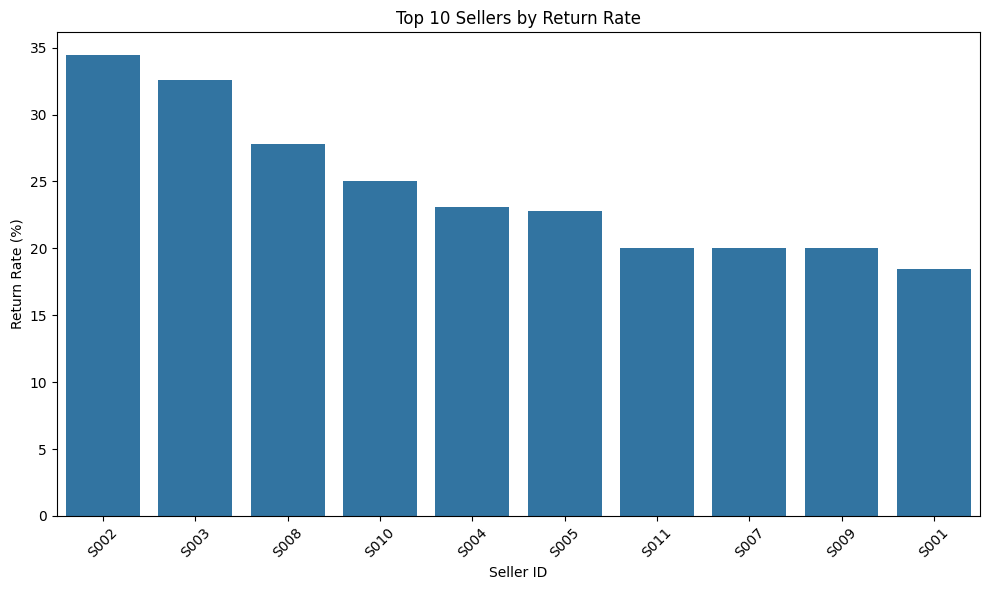

In [53]:
top_sellers = seller_analysis.head(10).reset_index()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_sellers,
    x="seller_id",
    y="return_rate"
)

plt.title("Top 10 Sellers by Return Rate")
plt.xlabel("Seller ID")
plt.ylabel("Return Rate (%)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [54]:
customer_analysis = (
    master_df.groupby("customer_segment")
    .agg(
        total_orders=("order_id", "nunique"),
        returned_orders=("is_returned", "sum")
    )
)

customer_analysis["return_rate"] = (
    customer_analysis["returned_orders"]
    / customer_analysis["total_orders"]
) * 100

display(customer_analysis)

,total_orders,returned_orders,return_rate
customer_segment,,,
Loyal,223,46,20.627803
New,141,43,30.496454
Returning,236,49,20.762712


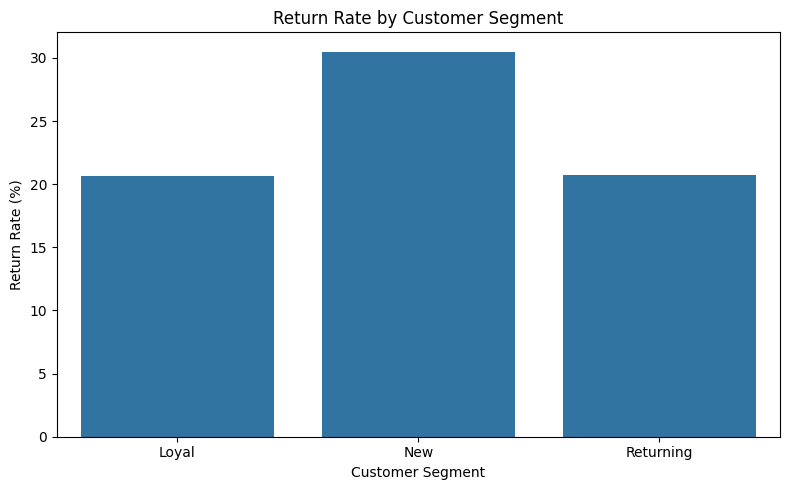

In [55]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=customer_analysis.reset_index(),
    x="customer_segment",
    y="return_rate"
)

plt.title("Return Rate by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Return Rate (%)")

plt.tight_layout()
plt.show()

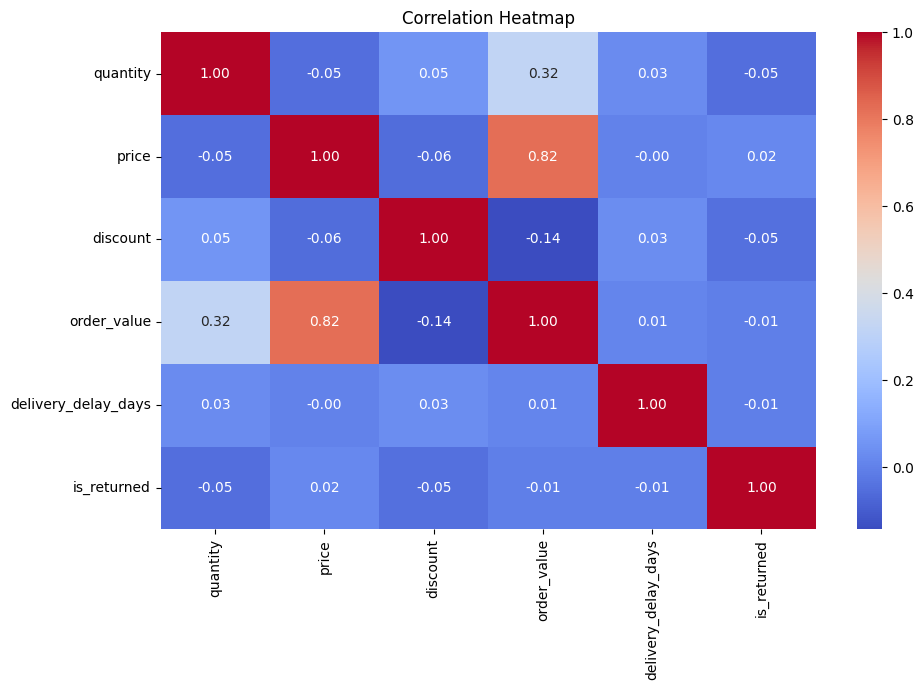

In [56]:
numerical_columns = [
    "quantity",
    "price",
    "discount",
    "order_value",
    "delivery_delay_days",
    "is_returned"
]

correlation_matrix = master_df[
    numerical_columns
].corr(numeric_only=True)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [57]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

# Create model dataset
model_df = master_df.copy()

# Target must be available
model_df = model_df[
    model_df["is_returned"].notna()
].copy()

# Remove identifiers and post-return information
drop_columns = [
    "order_id",
    "product_id",
    "customer_id",
    "return_flag",
    "is_returned",
    "reason",
    "return_date",
    "order_date",
    "delivered_date",
    "promised_date"
]

X = model_df.drop(
    columns=drop_columns,
    errors="ignore"
)

y = model_df["is_returned"].astype(int)

# Remove any remaining unsupported columns if necessary
X = X.drop(
    columns=["return_id"],
    errors="ignore"
)

categorical_features = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['quantity', 'price', 'discount', 'order_history', 'order_value', 'delivery_delay_days', 'order_month']
Categorical features: ['category', 'brand', 'size', 'seller_id', 'product_name', 'region', 'customer_segment', 'courier', 'delivery_status', 'discount_category']


In [59]:
# Create a fresh copy of the feature dataset
X = X.copy()

# Convert Pandas nullable string/category columns to object
for col in X.columns:
    if (
        isinstance(X[col].dtype, pd.StringDtype)
        or isinstance(X[col].dtype, pd.CategoricalDtype)
    ):
        X[col] = X[col].astype(object)

# Replace Pandas missing values with NumPy NaN
X = X.replace({pd.NA: np.nan})

# Check missing values
print("Missing values in X:")
print(X.isnull().sum())

print("\nData types:")
print(X.dtypes)

Missing values in X:
quantity                 0
price                    0
discount                 0
category                 0
brand                    0
size                   336
seller_id                0
product_name             0
region                   0
order_history            0
customer_segment         0
courier                  0
order_value              0
delivery_delay_days      2
delivery_status          0
order_month              0
discount_category        0
dtype: int64

Data types:
quantity                 int64
price                  float64
discount               float64
category                object
brand                   object
size                    object
seller_id               object
product_name            object
region                  object
order_history            int64
customer_segment        object
courier                 object
order_value            float64
delivery_delay_days    float64
delivery_status         object
order_month              int3

In [60]:
from sklearn.model_selection import train_test_split

# Ensure target contains valid integer values
y = y.astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 480
Testing rows: 120


In [61]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# Identify column types after cleaning
categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['quantity', 'price', 'discount', 'order_history', 'order_value', 'delivery_delay_days', 'order_month']
Categorical features: ['category', 'brand', 'size', 'seller_id', 'product_name', 'region', 'customer_segment', 'courier', 'delivery_status', 'discount_category']


In [62]:
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                class_weight="balanced"
            )
        )
    ]
)

print("Pipeline created successfully!")

Pipeline created successfully!


In [63]:
model.fit(X_train, y_train)

print("Model trained successfully! 🎉")

Model trained successfully! 🎉


In [64]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

y_pred = model.predict(X_test)

print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

if y_test.nunique() == 2:
    y_prob = model.predict_proba(X_test)[:, 1]

    print(
        "\nROC-AUC:",
        round(
            roc_auc_score(y_test, y_prob),
            3
        )
    )


Classification Report:
              precision    recall  f1-score   support

           0       0.77      1.00      0.87        92
           1       1.00      0.04      0.07        28

    accuracy                           0.78       120
   macro avg       0.89      0.52      0.47       120
weighted avg       0.83      0.78      0.68       120


Confusion Matrix:
[[92  0]
 [27  1]]

ROC-AUC: 0.422


In [65]:
# Get feature names after preprocessing
preprocessor = model.named_steps["preprocessor"]
classifier = model.named_steps["classifier"]

feature_names = preprocessor.get_feature_names_out()
importance = classifier.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

display(feature_importance_df.head(15))

,Feature,Importance
3,num__order_history,0.080458
4,num__order_value,0.072650
1,num__price,0.071211
6,num__order_month,0.050655
5,num__delivery_delay_days,0.042667
2,num__discount,0.039489
0,num__quantity,0.030958
114,cat__customer_segment_New,0.018495
113,cat__customer_segment_Loyal,0.016248
118,cat__courier_QuickKart,0.015591


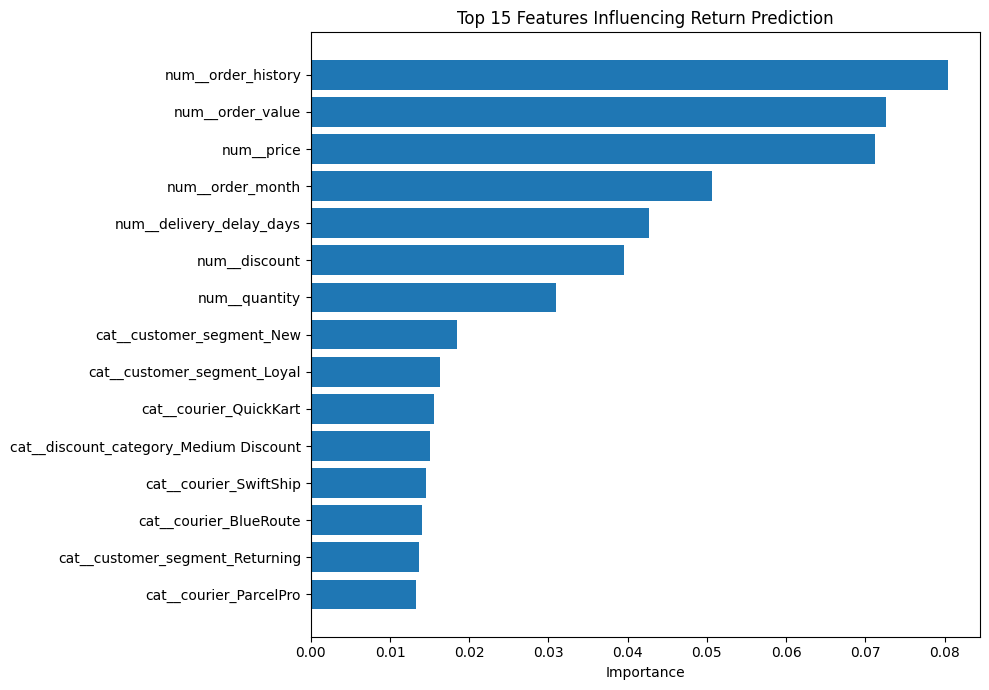

In [66]:
import matplotlib.pyplot as plt

top_features = feature_importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Importance")
plt.title("Top 15 Features Influencing Return Prediction")
plt.tight_layout()
plt.show()

In [67]:
total_orders = master_df["order_id"].nunique()
returned_orders = master_df.loc[
    master_df["is_returned"] == 1, "order_id"
].nunique()

return_rate = (
    returned_orders / total_orders * 100
    if total_orders else 0
)

print("Total Orders:", total_orders)
print("Returned Orders:", returned_orders)
print(f"Return Rate: {return_rate:.2f}%")

Total Orders: 600
Returned Orders: 138
Return Rate: 23.00%


In [68]:
category_returns = master_df.groupby("category").agg(
    Total_Orders=("order_id", "nunique"),
    Returned_Orders=("is_returned", "sum")
)

category_returns["Return_Rate_%"] = (
    category_returns["Returned_Orders"]
    / category_returns["Total_Orders"].replace(0, np.nan)
    * 100
)

display(category_returns.sort_values(
    "Return_Rate_%", ascending=False
))

,Total_Orders,Returned_Orders,Return_Rate_%
category,,,
Home & Kitchen,116,33,28.448276
Clothing,143,33,23.076923
Electronics,102,23,22.549020
Footwear,121,26,21.487603
Beauty,118,23,19.491525


In [69]:
master_df["discount_group"] = pd.cut(
    master_df["discount"],
    bins=[-0.01, 10, 20, 30, 50, 100],
    labels=["0-10%", "10-20%", "20-30%", "30-50%", "50-100%"]
)

discount_analysis = master_df.groupby(
    "discount_group", observed=False
).agg(
    Total_Orders=("order_id", "nunique"),
    Returned_Orders=("is_returned", "sum")
)

discount_analysis["Return_Rate_%"] = (
    discount_analysis["Returned_Orders"]
    / discount_analysis["Total_Orders"].replace(0, np.nan)
    * 100
)

display(discount_analysis)


,Total_Orders,Returned_Orders,Return_Rate_%
discount_group,,,
0-10%,256,58,22.656250
10-20%,202,56,27.722772
20-30%,127,21,16.535433
30-50%,15,3,20.000000
50-100%,0,0,NaN


In [70]:
delivery_analysis = master_df.groupby("delivery_status").agg(
    Total_Orders=("order_id", "nunique"),
    Returned_Orders=("is_returned", "sum")
)

delivery_analysis["Return_Rate_%"] = (
    delivery_analysis["Returned_Orders"]
    / delivery_analysis["Total_Orders"].replace(0, np.nan)
    * 100
)

display(delivery_analysis)

,Total_Orders,Returned_Orders,Return_Rate_%
delivery_status,,,
Early,14,3,21.428571
Late,448,102,22.767857
On Time,136,32,23.529412
Unknown,2,1,50.000000


In [71]:
reason_analysis = master_df.loc[
    master_df["is_returned"] == 1
].groupby("reason").size().sort_values(ascending=False)

display(reason_analysis)

,0
reason,
Damaged product,33
Wrong size,32
Not as described,23
Late delivery,20
Changed mind,7
Wrong item,6


In [72]:
master_df.to_csv(
    "/content/ecommerce_return_insight_cleaned.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [73]:
orders_clean.to_csv(
    "/content/orders_cleaned.csv", index=False
)

products_clean.to_csv(
    "/content/products_cleaned.csv", index=False
)

customers_clean.to_csv(
    "/content/customers_cleaned.csv", index=False
)

delivery_clean.to_csv(
    "/content/delivery_cleaned.csv", index=False
)

returns_clean.to_csv(
    "/content/returns_cleaned.csv", index=False
)

In [75]:
from google.colab import files

files.download("/content/ecommerce_return_insight_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [76]:
preprocessor = model.named_steps["preprocessor"]
classifier = model.named_steps["classifier"]

feature_names = preprocessor.get_feature_names_out()
importance = classifier.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

display(feature_importance_df.head(15))

,Feature,Importance
3,num__order_history,0.080458
4,num__order_value,0.072650
1,num__price,0.071211
6,num__order_month,0.050655
5,num__delivery_delay_days,0.042667
2,num__discount,0.039489
0,num__quantity,0.030958
114,cat__customer_segment_New,0.018495
113,cat__customer_segment_Loyal,0.016248
118,cat__courier_QuickKart,0.015591


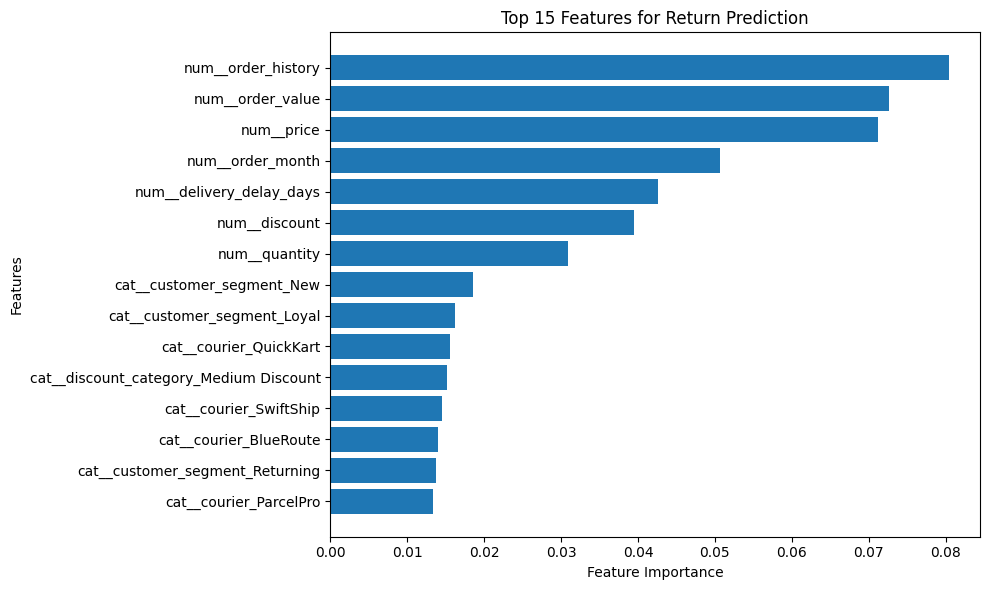

In [77]:
import matplotlib.pyplot as plt

top_features = feature_importance_df.head(15).sort_values(
    "Importance", ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Features for Return Prediction")
plt.tight_layout()
plt.show()

In [78]:
master_df.to_csv(
    "/content/ecommerce_return_insight_cleaned.csv",
    index=False
)

print("Dataset exported successfully!")

Dataset exported successfully!


Numeric features: ['quantity', 'price', 'discount', 'order_history', 'order_value']
Categorical features: ['category', 'brand', 'size', 'seller_id', 'product_name', 'region', 'customer_segment', 'courier', 'discount_category', 'discount_group']
Training shape: (480, 15)
Testing shape: (120, 15)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Baseline Random Forest,0.758,0.333,0.036,0.065,0.424
1,Balanced Random Forest,0.775,1.000,0.036,0.069,0.384


Selected Model: Balanced Random Forest

Classification Report:
              precision    recall  f1-score   support

           0       0.77      1.00      0.87        92
           1       1.00      0.04      0.07        28

    accuracy                           0.78       120
   macro avg       0.89      0.52      0.47       120
weighted avg       0.83      0.78      0.68       120

ROC-AUC: 0.384


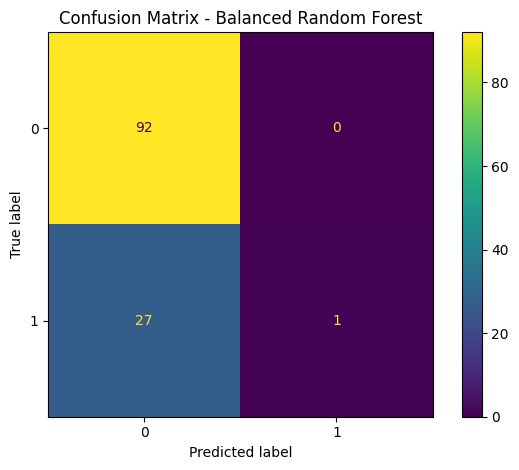

Random Forest training and evaluation completed!


In [80]:
# STEP 1: Improved Random Forest model - FIXED

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Prepare target
y = pd.to_numeric(
    master_df["is_returned"],
    errors="coerce"
).fillna(0).astype(int)

# 2. Remove target, identifiers and post-order information
drop_cols = [
    "is_returned",
    "return_flag",
    "return_flag_x",
    "return_flag_y",
    "reason",
    "reason_x",
    "reason_y",
    "return_date",
    "return_date_x",
    "return_date_y",
    "order_id",
    "customer_id",
    "product_id",
    "order_date",
    "promised_date",
    "delivered_date",
    "delivery_delay_days",
    "delivery_status",
    "order_month"
]

X = master_df.drop(
    columns=drop_cols,
    errors="ignore"
).copy()

# 3. Remove columns containing only missing values
X = X.dropna(axis=1, how="all")

# 4. Convert every feature to a compatible dtype
for col in X.columns:

    # Convert datetime columns to strings
    if pd.api.types.is_datetime64_any_dtype(X[col]):
        X[col] = X[col].astype("string")

    # Convert nullable numeric columns to standard numeric values
    elif pd.api.types.is_numeric_dtype(X[col]):
        X[col] = pd.to_numeric(
            X[col], errors="coerce"
        ).astype("float64")

    # Convert other columns to object and replace missing values
    else:
        X[col] = X[col].astype(object)
        X[col] = X[col].map(
            lambda value: (
                np.nan if pd.isna(value) else str(value)
            )
        )

# 5. Remove constant columns
constant_cols = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

X = X.drop(columns=constant_cols)

# 6. Final cleanup: remove any remaining pandas.NA
for col in X.columns:

    if X[col].dtype == object:
        X[col] = X[col].map(
            lambda value: (
                np.nan if pd.isna(value) else value
            )
        )

# 7. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 8. Identify numeric and categorical columns
numeric_cols = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Numeric features:", numeric_cols)
print("Categorical features:", categorical_cols)
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

# 9. Preprocessing pipelines
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="most_frequent",
            keep_empty_features=True
        )
    ),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []

if numeric_cols:
    transformers.append(
        ("numeric", numeric_pipeline, numeric_cols)
    )

if categorical_cols:
    transformers.append(
        ("categorical", categorical_pipeline, categorical_cols)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

# 10. Compare two Random Forest models
models = {
    "Baseline Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "Balanced Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )
}

trained_models = {}
evaluation_results = []

for name, classifier in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, probabilities
        )
    })

    trained_models[name] = pipeline

# 11. Compare results
evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df.round(3))

# Select the model with highest recall, using F1 as tie-breaker
best_model_name = (
    evaluation_df
    .sort_values(
        ["Recall", "F1 Score"],
        ascending=False
    )
    .iloc[0]["Model"]
)

model = trained_models[best_model_name]

print("Selected Model:", best_model_name)

# 12. Evaluate selected model
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, y_prob), 3
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

print("Random Forest training and evaluation completed!")

Top 15 Important Features:


,Feature,Importance
0,numeric__order_history,0.088010
1,numeric__order_value,0.085600
2,numeric__price,0.082957
3,numeric__discount,0.038965
4,numeric__quantity,0.038557
5,categorical__customer_segment_New,0.019388
6,categorical__courier_QuickKart,0.018029
7,categorical__customer_segment_Loyal,0.017667
8,categorical__courier_BlueRoute,0.017610
9,categorical__courier_SwiftShip,0.017499


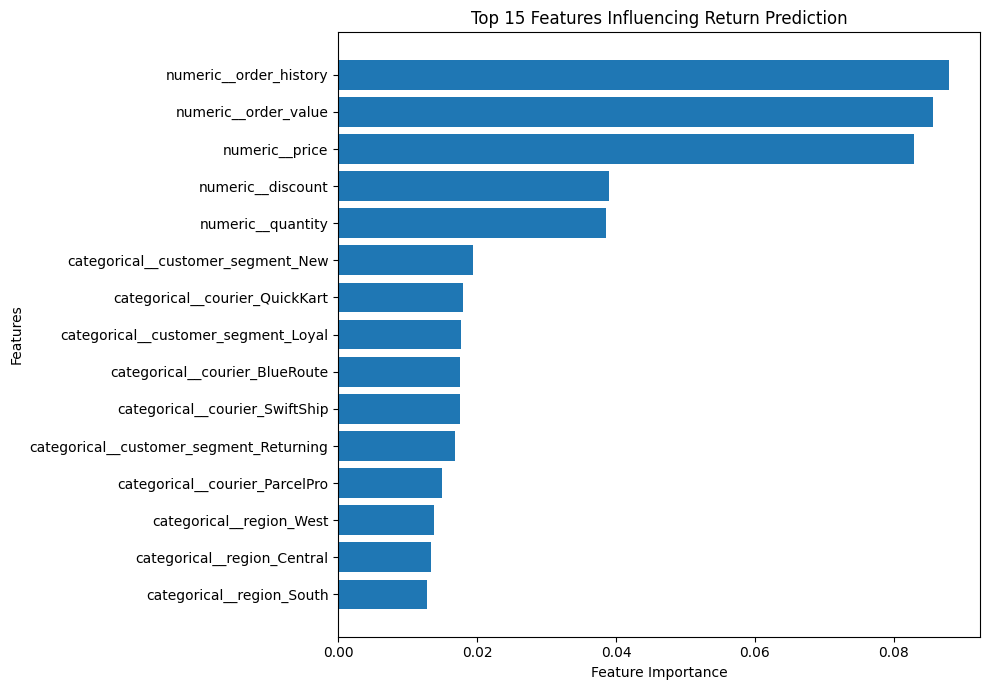

Feature importance analysis completed!


In [81]:
# STEP 2: Feature Importance Analysis

import pandas as pd
import matplotlib.pyplot as plt

# Get the trained model components
preprocessor = model.named_steps["preprocessor"]
classifier = model.named_steps["classifier"]

# Extract feature names and importance scores
feature_names = preprocessor.get_feature_names_out()
importance_values = classifier.feature_importances_

# Create feature importance DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
}).sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display top 15 features
print("Top 15 Important Features:")
display(feature_importance_df.head(15))

# Visualize the results
top_features = (
    feature_importance_df.head(15)
    .sort_values(by="Importance", ascending=True)
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Features Influencing Return Prediction")

plt.tight_layout()
plt.show()

print("Feature importance analysis completed!")

MODEL EVALUATION RESULTS


,Metric,Score
0,Accuracy,0.7750
1,Precision,1.0000
2,Recall,0.0357
3,F1 Score,0.0690


ROC-AUC Score: 0.3841

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.77      1.00      0.87        92
           1       1.00      0.04      0.07        28

    accuracy                           0.78       120
   macro avg       0.89      0.52      0.47       120
weighted avg       0.83      0.78      0.68       120



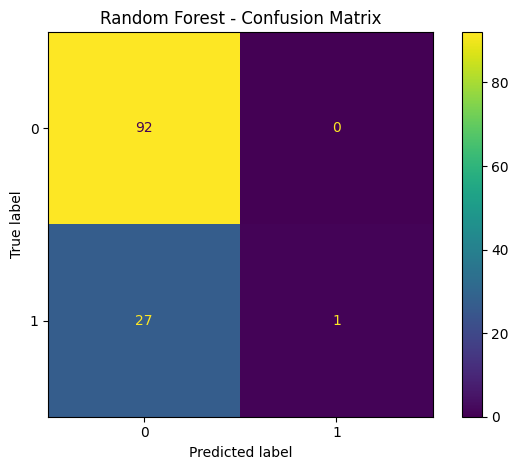

Model evaluation completed!


In [82]:
# STEP 3: Model Evaluation

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score
)

# Make predictions using the trained model
y_pred = model.predict(X_test)

# Get prediction probabilities if supported
y_prob = None

if hasattr(model, "predict_proba"):
    y_prob = model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
evaluation_results = {
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ]
}

evaluation_df = pd.DataFrame(evaluation_results)

print("MODEL EVALUATION RESULTS")
display(evaluation_df.round(4))

# ROC-AUC
if y_prob is not None and len(pd.Series(y_test).unique()) == 2:
    print(
        "ROC-AUC Score:",
        round(roc_auc_score(y_test, y_prob), 4)
    )

# Classification report
print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm
).plot()

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

print("Model evaluation completed!")

In [83]:
# STEP 4: BUSINESS ANALYSIS TABLES

import pandas as pd
import numpy as np

# Work with the cleaned master dataset
df = master_df.copy()

# Normalize column names for easier access
df.columns = df.columns.str.strip().str.lower()

print("Dataset shape:", df.shape)
print("Available columns:")
print(df.columns.tolist())

Dataset shape: (600, 28)
Available columns:
['order_id', 'order_date', 'product_id', 'customer_id', 'quantity', 'price', 'discount', 'category', 'brand', 'size', 'seller_id', 'product_name', 'region', 'order_history', 'customer_segment', 'promised_date', 'delivered_date', 'courier', 'order_value', 'delivery_delay_days', 'return_flag', 'reason', 'return_date', 'is_returned', 'delivery_status', 'order_month', 'discount_category', 'discount_group']


In [84]:
# Identify the return indicator column
possible_return_cols = [
    "return_flag",
    "is_returned",
    "returned",
    "return_status"
]

return_col = next(
    (col for col in possible_return_cols if col in df.columns),
    None
)

if return_col is None:
    raise ValueError(
        "Return indicator not found. Check the column names above."
    )

# Convert the return indicator into 0/1
if df[return_col].dtype == "object":
    df[return_col] = (
        df[return_col]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({
            "yes": 1,
            "true": 1,
            "returned": 1,
            "1": 1,
            "no": 0,
            "false": 0,
            "not returned": 0,
            "0": 0
        })
    )

df[return_col] = pd.to_numeric(df[return_col], errors="coerce")

# Identify the category column
category_col = next(
    (col for col in ["category", "product_category"]
     if col in df.columns),
    None
)

if category_col:
    category_analysis = (
        df.groupby(category_col, dropna=False)
        .agg(
            Total_Orders=(return_col, "count"),
            Returned_Orders=(return_col, "sum")
        )
        .reset_index()
    )

    category_analysis["Return_Rate_%"] = (
        category_analysis["Returned_Orders"]
        / category_analysis["Total_Orders"] * 100
    ).round(2)

    category_analysis = category_analysis.sort_values(
        "Return_Rate_%", ascending=False
    )

    print("CATEGORY-WISE RETURN ANALYSIS")
    display(category_analysis)
else:
    print("Category column not found.")

CATEGORY-WISE RETURN ANALYSIS


,category,Total_Orders,Returned_Orders,Return_Rate_%
4,Home & Kitchen,116,33,28.45
1,Clothing,143,33,23.08
2,Electronics,102,23,22.55
3,Footwear,121,26,21.49
0,Beauty,118,23,19.49


In [85]:
discount_col = next(
    (col for col in ["discount", "discount_percentage",
                     "discount_percent", "discount_rate"]
     if col in df.columns),
    None
)

if discount_col:
    df[discount_col] = pd.to_numeric(
        df[discount_col], errors="coerce"
    )

    df["Discount_Band"] = pd.cut(
        df[discount_col],
        bins=[-np.inf, 0, 10, 20, 30, np.inf],
        labels=[
            "No Discount",
            "1–10%",
            "11–20%",
            "21–30%",
            "Above 30%"
        ],
        include_lowest=True
    )

    discount_analysis = (
        df.groupby("Discount_Band", observed=False)
        .agg(
            Total_Orders=(return_col, "count"),
            Returned_Orders=(return_col, "sum")
        )
        .reset_index()
    )

    discount_analysis["Return_Rate_%"] = (
        discount_analysis["Returned_Orders"]
        / discount_analysis["Total_Orders"].replace(0, np.nan)
        * 100
    ).round(2)

    print("DISCOUNT-WISE RETURN ANALYSIS")
    display(discount_analysis)
else:
    discount_analysis = pd.DataFrame()
    print("Discount column not found.")

DISCOUNT-WISE RETURN ANALYSIS


,Discount_Band,Total_Orders,Returned_Orders,Return_Rate_%
0,No Discount,83,18,21.69
1,1–10%,173,40,23.12
2,11–20%,202,56,27.72
3,21–30%,127,21,16.54
4,Above 30%,15,3,20.00


In [86]:
discount_col = next(
    (col for col in ["discount", "discount_percentage",
                     "discount_percent", "discount_rate"]
     if col in df.columns),
    None
)

if discount_col:
    df[discount_col] = pd.to_numeric(
        df[discount_col], errors="coerce"
    )

    df["Discount_Band"] = pd.cut(
        df[discount_col],
        bins=[-np.inf, 0, 10, 20, 30, np.inf],
        labels=[
            "No Discount",
            "1–10%",
            "11–20%",
            "21–30%",
            "Above 30%"
        ],
        include_lowest=True
    )

    discount_analysis = (
        df.groupby("Discount_Band", observed=False)
        .agg(
            Total_Orders=(return_col, "count"),
            Returned_Orders=(return_col, "sum")
        )
        .reset_index()
    )

    discount_analysis["Return_Rate_%"] = (
        discount_analysis["Returned_Orders"]
        / discount_analysis["Total_Orders"].replace(0, np.nan)
        * 100
    ).round(2)

    print("DISCOUNT-WISE RETURN ANALYSIS")
    display(discount_analysis)
else:
    discount_analysis = pd.DataFrame()
    print("Discount column not found.")

DISCOUNT-WISE RETURN ANALYSIS


,Discount_Band,Total_Orders,Returned_Orders,Return_Rate_%
0,No Discount,83,18,21.69
1,1–10%,173,40,23.12
2,11–20%,202,56,27.72
3,21–30%,127,21,16.54
4,Above 30%,15,3,20.00


In [87]:
delivery_col = next(
    (col for col in ["delivery_delay_days", "delay_days",
                     "delivery_days_late", "late_delivery_days"]
     if col in df.columns),
    None
)

if delivery_col:
    df[delivery_col] = pd.to_numeric(
        df[delivery_col], errors="coerce"
    )

    df["Delivery_Status"] = np.where(
        df[delivery_col] > 0,
        "Late Delivery",
        "On-Time / Early Delivery"
    )

    delivery_analysis = (
        df.groupby("Delivery_Status")
        .agg(
            Total_Orders=(return_col, "count"),
            Returned_Orders=(return_col, "sum")
        )
        .reset_index()
    )

    delivery_analysis["Return_Rate_%"] = (
        delivery_analysis["Returned_Orders"]
        / delivery_analysis["Total_Orders"].replace(0, np.nan)
        * 100
    ).round(2)

    print("DELIVERY-WISE RETURN ANALYSIS")
    display(delivery_analysis)
else:
    delivery_analysis = pd.DataFrame()
    print("Delivery delay column not found.")

DELIVERY-WISE RETURN ANALYSIS


,Delivery_Status,Total_Orders,Returned_Orders,Return_Rate_%
0,Late Delivery,448,102,22.77
1,On-Time / Early Delivery,152,36,23.68


In [88]:
reason_col = next(
    (col for col in ["return_reason", "reason", "return_cause"]
     if col in df.columns),
    None
)

if reason_col:
    reason_analysis = (
        df[df[return_col] == 1][reason_col]
        .fillna("Unknown")
        .astype(str)
        .value_counts()
        .rename_axis("Return_Reason")
        .reset_index(name="Return_Count")
    )

    print("RETURN REASONS")
    display(reason_analysis)
else:
    reason_analysis = pd.DataFrame()
    print("Return reason column not found.")

RETURN REASONS


,Return_Reason,Return_Count
0,Damaged product,33
1,Wrong size,32
2,Not as described,23
3,Late delivery,20
4,Unknown,17
5,Changed mind,7
6,Wrong item,6


In [89]:
seller_col = next(
    (col for col in ["seller_id", "seller_name", "seller"]
     if col in df.columns),
    None
)

if seller_col:
    seller_analysis = (
        df.groupby(seller_col, dropna=False)
        .agg(
            Total_Orders=(return_col, "count"),
            Returned_Orders=(return_col, "sum")
        )
        .reset_index()
    )

    seller_analysis["Return_Rate_%"] = (
        seller_analysis["Returned_Orders"]
        / seller_analysis["Total_Orders"].replace(0, np.nan)
        * 100
    ).round(2)

    seller_analysis = seller_analysis.sort_values(
        "Return_Rate_%", ascending=False
    )

    print("SELLER-WISE RETURN ANALYSIS")
    display(seller_analysis)
else:
    seller_analysis = pd.DataFrame()
    print("Seller column not found.")

SELLER-WISE RETURN ANALYSIS


,seller_id,Total_Orders,Returned_Orders,Return_Rate_%
1,S002,61,21,34.43
2,S003,43,14,32.56
7,S008,54,15,27.78
9,S010,72,18,25.00
3,S004,52,12,23.08
4,S005,79,18,22.78
10,S011,20,4,20.00
6,S007,40,8,20.00
8,S009,50,10,20.00
0,S001,38,7,18.42


In [90]:
# STEP 5: EXPORT ANALYSIS TABLES TO EXCEL

output_file = "/content/Ecommerce_Return_Analysis.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:

    df.to_excel(
        writer,
        sheet_name="Cleaned_Data",
        index=False
    )

    if "category_analysis" in globals() and not category_analysis.empty:
        category_analysis.to_excel(
            writer, sheet_name="Category_Analysis", index=False
        )

    if "discount_analysis" in globals() and not discount_analysis.empty:
        discount_analysis.to_excel(
            writer, sheet_name="Discount_Analysis", index=False
        )

    if "delivery_analysis" in globals() and not delivery_analysis.empty:
        delivery_analysis.to_excel(
            writer, sheet_name="Delivery_Analysis", index=False
        )

    if "reason_analysis" in globals() and not reason_analysis.empty:
        reason_analysis.to_excel(
            writer, sheet_name="Return_Reasons", index=False
        )

    if "seller_analysis" in globals() and not seller_analysis.empty:
        seller_analysis.to_excel(
            writer, sheet_name="Seller_Analysis", index=False
        )

    if "feature_importance_df" in globals():
        feature_importance_df.to_excel(
            writer, sheet_name="Feature_Importance", index=False
        )

    if "evaluation_df" in globals():
        evaluation_df.to_excel(
            writer, sheet_name="Model_Evaluation", index=False
        )

print("Excel file created:", output_file)

from google.colab import files
files.download(output_file)

Excel file created: /content/Ecommerce_Return_Analysis.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [91]:
# STEP 6: E-COMMERCE RETURN INSIGHT DASHBOARD

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.chart import BarChart, PieChart, Reference
from openpyxl.utils import get_column_letter

# --------------------------------------------------
# 1. PREPARE DATA
# --------------------------------------------------

df = master_df.copy()
df.columns = df.columns.str.strip().str.lower()

return_col = next(
    (c for c in ["return_flag", "is_returned", "returned",
                 "return_status"] if c in df.columns),
    None
)

if return_col is None:
    raise ValueError(
        "Return indicator not found. Check master_df.columns."
    )

# Normalize return indicator
if df[return_col].dtype == "object":
    df[return_col] = (
        df[return_col].astype(str).str.strip().str.lower()
        .map({
            "1": 1, "true": 1, "yes": 1, "returned": 1,
            "0": 0, "false": 0, "no": 0,
            "not returned": 0
        })
    )

df[return_col] = pd.to_numeric(df[return_col], errors="coerce")

valid_df = df.dropna(subset=[return_col]).copy()
valid_df[return_col] = valid_df[return_col].astype(int)

total_orders = len(valid_df)
returned_orders = int(valid_df[return_col].sum())
return_rate = (
    returned_orders / total_orders * 100
    if total_orders else 0
)
non_returned = total_orders - returned_orders

print("Total Orders:", total_orders)
print("Returned Orders:", returned_orders)
print("Non-Returned Orders:", non_returned)
print(f"Return Rate: {return_rate:.2f}%")

# --------------------------------------------------
# 2. PREPARE DASHBOARD SUMMARY
# --------------------------------------------------

summary = pd.DataFrame({
    "Metric": [
        "Total Orders",
        "Returned Orders",
        "Non-Returned Orders",
        "Return Rate (%)"
    ],
    "Value": [
        total_orders,
        returned_orders,
        non_returned,
        round(return_rate, 2)
    ]
})

# --------------------------------------------------
# 3. COLLECT AVAILABLE ANALYSIS TABLES
# --------------------------------------------------

analysis_tables = {
    "Category_Analysis": globals().get(
        "category_analysis", pd.DataFrame()
    ),
    "Discount_Analysis": globals().get(
        "discount_analysis", pd.DataFrame()
    ),
    "Delivery_Analysis": globals().get(
        "delivery_analysis", pd.DataFrame()
    ),
    "Seller_Analysis": globals().get(
        "seller_analysis", pd.DataFrame()
    ),
    "Return_Reasons": globals().get(
        "reason_analysis", pd.DataFrame()
    ),
    "Feature_Importance": globals().get(
        "feature_importance_df", pd.DataFrame()
    ),
    "Model_Evaluation": globals().get(
        "evaluation_df", pd.DataFrame()
    )
}

output_file = "/content/Ecommerce_Return_Insight_Dashboard.xlsx"

# --------------------------------------------------
# 4. EXPORT WORKBOOK
# --------------------------------------------------

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:

    summary.to_excel(
        writer,
        sheet_name="Dashboard",
        index=False,
        startrow=2
    )

    valid_df.to_excel(
        writer,
        sheet_name="Cleaned_Data",
        index=False
    )

    for sheet_name, table in analysis_tables.items():
        if isinstance(table, pd.DataFrame) and not table.empty:
            table.to_excel(
                writer,
                sheet_name=sheet_name[:31],
                index=False
            )

# --------------------------------------------------
# 5. FORMAT WORKBOOK
# --------------------------------------------------

wb = load_workbook(output_file)
ws = wb["Dashboard"]

ws["A1"] = "E-COMMERCE RETURN INSIGHT DASHBOARD"
ws["A1"].font = Font(
    size=18,
    bold=True,
    color="FFFFFF"
)
ws["A1"].fill = PatternFill(
    "solid",
    fgColor="1F4E78"
)
ws.merge_cells("A1:B1")
ws["A1"].alignment = Alignment(horizontal="center")

for cell in ws[3]:
    cell.font = Font(bold=True, color="FFFFFF")
    cell.fill = PatternFill("solid", fgColor="4472C4")

for column in ws.columns:
    max_length = max(
        len(str(cell.value or "")) for cell in column
    )
    ws.column_dimensions[
        get_column_letter(column[0].column)
    ].width = min(max_length + 4, 35)

# --------------------------------------------------
# 6. CATEGORY RETURN-RATE CHART
# --------------------------------------------------

if "Category_Analysis" in wb.sheetnames:
    cat_ws = wb["Category_Analysis"]

    headers = {
        cell.value: cell.column
        for cell in cat_ws[1]
    }

    category_key = next(
        (k for k in headers if "category" in str(k).lower()),
        None
    )

    rate_key = next(
        (k for k in headers if "return_rate" in str(k).lower()),
        None
    )

    if category_key and rate_key and cat_ws.max_row > 1:
        chart = BarChart()
        chart.type = "bar"
        chart.style = 10
        chart.title = "Return Rate by Category"
        chart.x_axis.title = "Return Rate (%)"
        chart.y_axis.title = "Category"

        data = Reference(
            cat_ws,
            min_col=headers[rate_key],
            min_row=1,
            max_row=cat_ws.max_row
        )

        categories = Reference(
            cat_ws,
            min_col=headers[category_key],
            min_row=2,
            max_row=cat_ws.max_row
        )

        chart.add_data(data, titles_from_data=True)
        chart.set_categories(categories)
        chart.height = 8
        chart.width = 15

        ws.add_chart(chart, "D3")

# --------------------------------------------------
# 7. RETURN REASONS CHART
# --------------------------------------------------

if "Return_Reasons" in wb.sheetnames:
    reason_ws = wb["Return_Reasons"]

    if reason_ws.max_row > 1 and reason_ws.max_column >= 2:
        chart = BarChart()
        chart.type = "col"
        chart.style = 11
        chart.title = "Orders by Return Reason"
        chart.y_axis.title = "Number of Returns"
        chart.x_axis.title = "Return Reason"

        data = Reference(
            reason_ws,
            min_col=2,
            min_row=1,
            max_row=reason_ws.max_row
        )

        categories = Reference(
            reason_ws,
            min_col=1,
            min_row=2,
            max_row=reason_ws.max_row
        )

        chart.add_data(data, titles_from_data=True)
        chart.set_categories(categories)
        chart.height = 8
        chart.width = 15

        ws.add_chart(chart, "D20")

# --------------------------------------------------
# 8. FINALIZE
# --------------------------------------------------

wb.save(output_file)

print("\nDashboard workbook created successfully!")
print("File:", output_file)

from google.colab import files
files.download(output_file)

Total Orders: 600
Returned Orders: 138
Non-Returned Orders: 462
Return Rate: 23.00%

Dashboard workbook created successfully!
File: /content/Ecommerce_Return_Insight_Dashboard.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Business Insights

### 1. Overall Return Rate
Out of 600 orders, 138 orders were returned, resulting in an overall return rate of 23%. This indicates that product returns are an important area for business improvement.

### 2. Category-wise Returns
Home & Kitchen recorded the highest return rate at approximately 28.45%, followed by Clothing at 23.08% and Electronics at 22.55%. The business should investigate the causes of returns in the Home & Kitchen category.

### 3. Return Reasons
Damaged products and wrong sizes were among the most frequently recorded return reasons. Better quality checks, secure packaging, and accurate size information may help reduce avoidable returns.

### 4. Discount Analysis
Discount levels should be compared with return rates to determine whether heavily discounted orders are associated with more returns. Business decisions should be based on the observed results.

### 5. Delivery Performance
Delivery delays should be analysed alongside return rates. If late deliveries are associated with higher returns, the business should review delivery partners and improve delivery-time monitoring.

### 6. Seller Performance
Seller-wise return rates can help identify sellers who may require additional quality checks or improvements in product descriptions and packaging.

### 7. Machine Learning Findings
A Random Forest classifier was developed to predict product returns. However, the model showed limited ability to identify returned orders. Its predictions should therefore be interpreted cautiously.

### Business Recommendations
- Improve product quality inspection and packaging.
- Provide accurate product descriptions, images, and size information.
- Investigate categories with high return rates.
- Monitor delivery performance and seller-wise returns.
- Continue collecting reliable return data to improve future analysis and prediction.


Final Conclusion
The E-Commerce Return Insight project analysed order, product, customer, delivery, and return information to understand product return patterns.

The datasets were cleaned and combined, and exploratory data analysis, visualizations, feature engineering, and Random Forest classification were performed.

The analysis covered product categories, discounts, delivery performance, sellers, and return reasons. Out of 600 orders, 138 were returned, giving an overall return rate of 23%. Home & Kitchen recorded the highest observed category return rate at approximately 28.45%.

The findings highlight opportunities to improve product quality, packaging, product descriptions, size information, and delivery performance.

Although a Random Forest model was developed, its ability to identify returned orders was limited. Further model improvement would be necessary before using its predictions for operational decisions.

Overall, this project demonstrates how data analysis can help e-commerce businesses understand return patterns, identify areas for improvement, and make data-driven decisions to improve customer satisfaction and reduce avoidable returns.